In [1]:
import os
import warnings
import gc
import inspect
import numpy as np
import matplotlib.pyplot as plt
import pynbody
import pynbody.plot.sph as sph
from pynbody.analysis import angmom, profile
from pynbody import filt
warnings.filterwarnings('ignore')

# High-quality plot aesthetics for the report
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 12, 'axes.labelsize': 13, 
    'axes.titlesize': 14, 'legend.fontsize': 11
})

print(f"Pynbody version: {pynbody.__version__}")
print(f"Working Directory: {os.getcwd()}")

# Verify all 5 files are present on the SSD
required_files = [
    'DG_project.pdf', 'run708main.01000', 'run708main.param',
    'run708mainDiff.01000', 'run708mainDiff.param'
]
for fname in required_files:
    assert os.path.exists(fname), f"Missing file: {fname}. Check your directory!"
print("All simulation and parameter files verified successfully.")

def render_sph_on_ax(sim_sub, ax, qty='rho', units='Msol kpc^-2', width='30 kpc', cmap='inferno', title=None):
    """Version-safe pynbody plotting wrapper for subplots."""
    sig = inspect.signature(sph.image)
    kwargs = dict(qty=qty, units=units, width=width, cmap=cmap)
    if 'axes' in sig.parameters: kwargs['axes'] = ax
    elif 'subplot' in sig.parameters: kwargs['subplot'] = ax
    im = sph.image(sim_sub, **kwargs)
    if title: ax.set_title(title, pad=10, fontweight='bold')
    return im

Pynbody version: 2.8.0
Working Directory: /Volumes/Sudipta_T7/GalDyn_project
All simulation and parameter files verified successfully.


In [2]:
# Force Apple Accelerate (BLAS) to use a single thread to prevent matrix math segfaults
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

def ultra_safe_faceon(sim, radius_kpc=10.0):
    print("     -> Calculating Center of Mass...")
    # Get raw numpy arrays to bypass C-extensions
    pos_s = np.array(sim.s['pos'])
    vel_s = np.array(sim.s['vel'])
    mass_s = np.array(sim.s['mass'])
    
    com_pos = np.average(pos_s, weights=mass_s, axis=0)
    com_vel = np.average(vel_s, weights=mass_s, axis=0)
    
    print("     -> Shifting coordinates to center...")
    sim['pos'] -= com_pos
    sim['vel'] -= com_vel
    
    print("     -> Filtering inner stars (Memory-efficient pure NumPy)...")
    # Pure numpy distance calculation (Bypasses pynbody.filt.Sphere memory spike)
    pos_s_new = np.array(sim.s['pos'])
    r = np.linalg.norm(pos_s_new, axis=1)
    mask = r < radius_kpc
    
    pos_in = pos_s_new[mask]
    vel_in = np.array(sim.s['vel'])[mask]
    mass_in = mass_s[mask]
    
    print("     -> Calculating angular momentum...")
    L = np.sum(mass_in[:, None] * np.cross(pos_in, vel_in), axis=0)
    L_norm = L / np.linalg.norm(L)
    
    print("     -> Applying rotation matrix to align face-on...")
    z_axis = np.array([0.0, 0.0, 1.0])
    v = np.cross(L_norm, z_axis)
    c = np.dot(L_norm, z_axis)
    s_val = np.linalg.norm(v)
    
    if s_val > 1e-6:
        vx = np.array([
            [0, -v[2], v[1]],
            [v[2], 0, -v[0]],
            [-v[1], v[0], 0]
        ])
        R = np.eye(3) + vx + np.dot(vx, vx) * ((1 - c) / (s_val**2))
        
        sim['pos'][:] = np.dot(np.array(sim['pos']), R.T)
        sim['vel'][:] = np.dot(np.array(sim['vel']), R.T)
    print("     -> Alignment complete!")

print("1. Loading ONLY run708main to conserve RAM...")
s_main = pynbody.load('run708main.01000')
s_main.physical_units(distance='kpc', velocity='km s^-1', mass='Msol')

print("2. Aligning run708main face-on...")
ultra_safe_faceon(s_main)
print(f"   -> run708main time: {s_main.properties['time'].in_units('Gyr'):.2f} Gyr\n")

# Force garbage collection to free up memory before loading the second massive file
gc.collect()

print("3. Loading run708mainDiff into RAM...")
s_diff = pynbody.load('run708mainDiff.01000')
s_diff.physical_units(distance='kpc', velocity='km s^-1', mass='Msol')

print("4. Aligning run708mainDiff face-on...")
ultra_safe_faceon(s_diff)
print(f"   -> run708mainDiff time: {s_diff.properties['time'].in_units('Gyr'):.2f} Gyr\n")

print("SUCCESS! Both galaxies are loaded and aligned.")

1. Loading ONLY run708main to conserve RAM...
2. Aligning run708main face-on...
     -> Calculating Center of Mass...
     -> Shifting coordinates to center...
     -> Filtering inner stars (Memory-efficient pure NumPy)...
     -> Calculating angular momentum...
     -> Applying rotation matrix to align face-on...
     -> Alignment complete!
   -> run708main time: 9.70 Gyr

3. Loading run708mainDiff into RAM...
4. Aligning run708mainDiff face-on...
     -> Calculating Center of Mass...
     -> Shifting coordinates to center...
     -> Filtering inner stars (Memory-efficient pure NumPy)...
     -> Calculating angular momentum...
     -> Applying rotation matrix to align face-on...
     -> Alignment complete!
   -> run708mainDiff time: 9.70 Gyr

SUCCESS! Both galaxies are loaded and aligned.


In [3]:
def print_component_masses(sim, sim_name):
    # Summing up masses directly via numpy to avoid Pynbody unit overhead issues
    m_star = np.sum(np.array(sim.s['mass']))
    m_gas  = np.sum(np.array(sim.g['mass']))
    m_dm   = np.sum(np.array(sim.dm['mass']))
    m_tot  = m_star + m_gas + m_dm

    print(f"========== {sim_name} ==========")
    print(f"Stellar Mass (.s)     : {m_star:.4e} Msol  (Particles: {len(sim.s):,})")
    print(f"Gas Mass (.g)         : {m_gas:.4e} Msol  (Particles: {len(sim.g):,})")
    print(f"Dark Matter Mass (.dm): {m_dm:.4e} Msol  (Particles: {len(sim.dm):,})")
    print(f"Total Mass            : {m_tot:.4e} Msol\n")

print_component_masses(s_main, "Run 708main")
print_component_masses(s_diff, "Run 708main Diff")

========== Run 708main ==========
Stellar Mass (.s)     : 6.5301e+10 Msol  (Particles: 11,146,828)
Gas Mass (.g)         : 6.9830e+10 Msol  (Particles: 2,599,914)
Dark Matter Mass (.dm): 1.2162e+12 Msol  (Particles: 5,000,000)
Total Mass            : 1.3513e+12 Msol

========== Run 708main Diff ==========
Stellar Mass (.s)     : 6.6929e+10 Msol  (Particles: 11,362,983)
Gas Mass (.g)         : 6.8203e+10 Msol  (Particles: 2,544,416)
Dark Matter Mass (.dm): 1.2162e+12 Msol  (Particles: 5,000,000)
Total Mass            : 1.3513e+12 Msol



Rendering Run 708main stellar map...
Rendering Run 708main Diff stellar map...


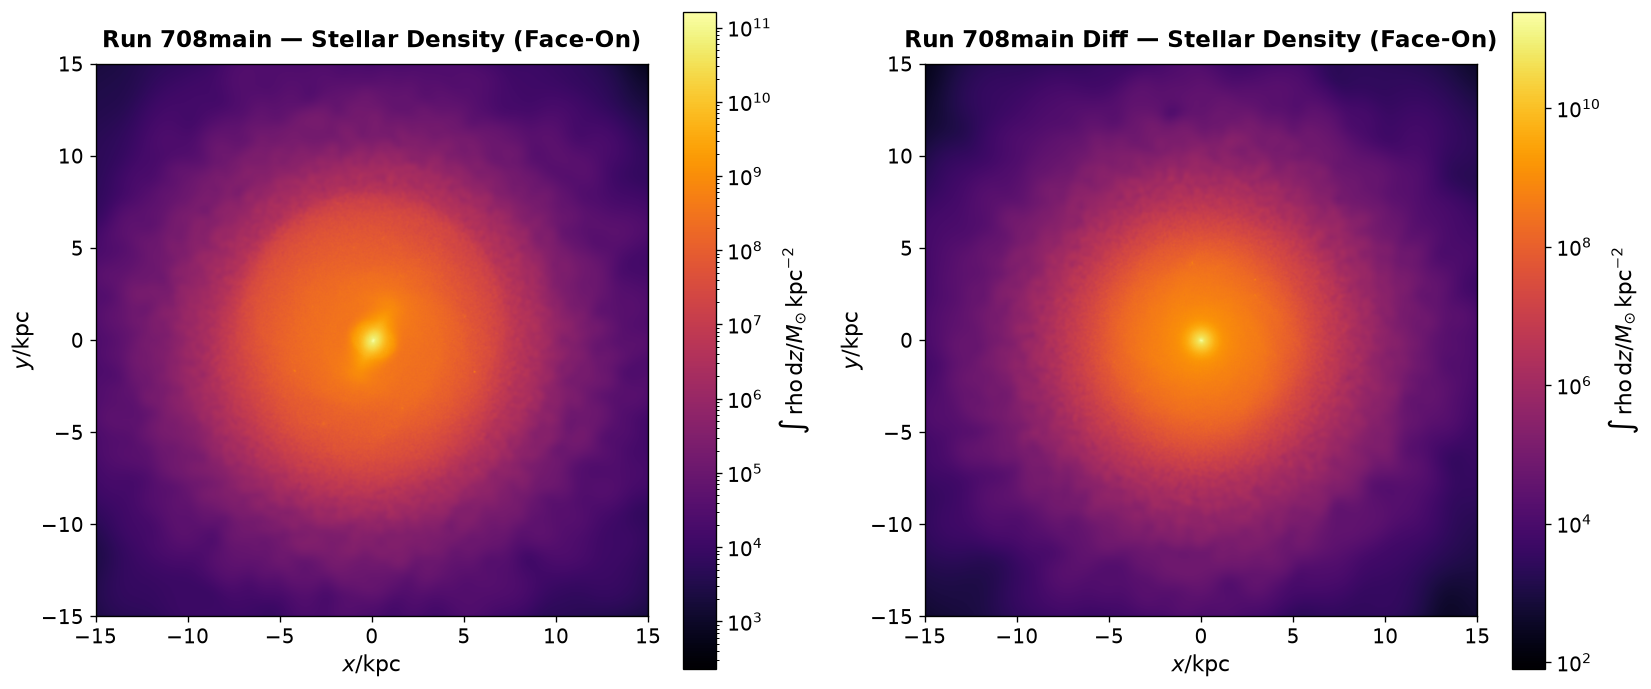

Saved as Task1_3_Stellar_FaceOn.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

print("Rendering Run 708main stellar map...")
render_sph_on_ax(
    s_main.s, axes[0],
    qty='rho', units='Msol kpc^-2', width='30 kpc', cmap='inferno',
    title='Run 708main — Stellar Density (Face-On)'
)

print("Rendering Run 708main Diff stellar map...")
render_sph_on_ax(
    s_diff.s, axes[1],
    qty='rho', units='Msol kpc^-2', width='30 kpc', cmap='inferno',
    title='Run 708main Diff — Stellar Density (Face-On)'
)

plt.tight_layout()
plt.savefig('Task1_3_Stellar_FaceOn.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved as Task1_3_Stellar_FaceOn.png")

Rendering Run 708main gas map...
Rendering Run 708main Diff gas map...


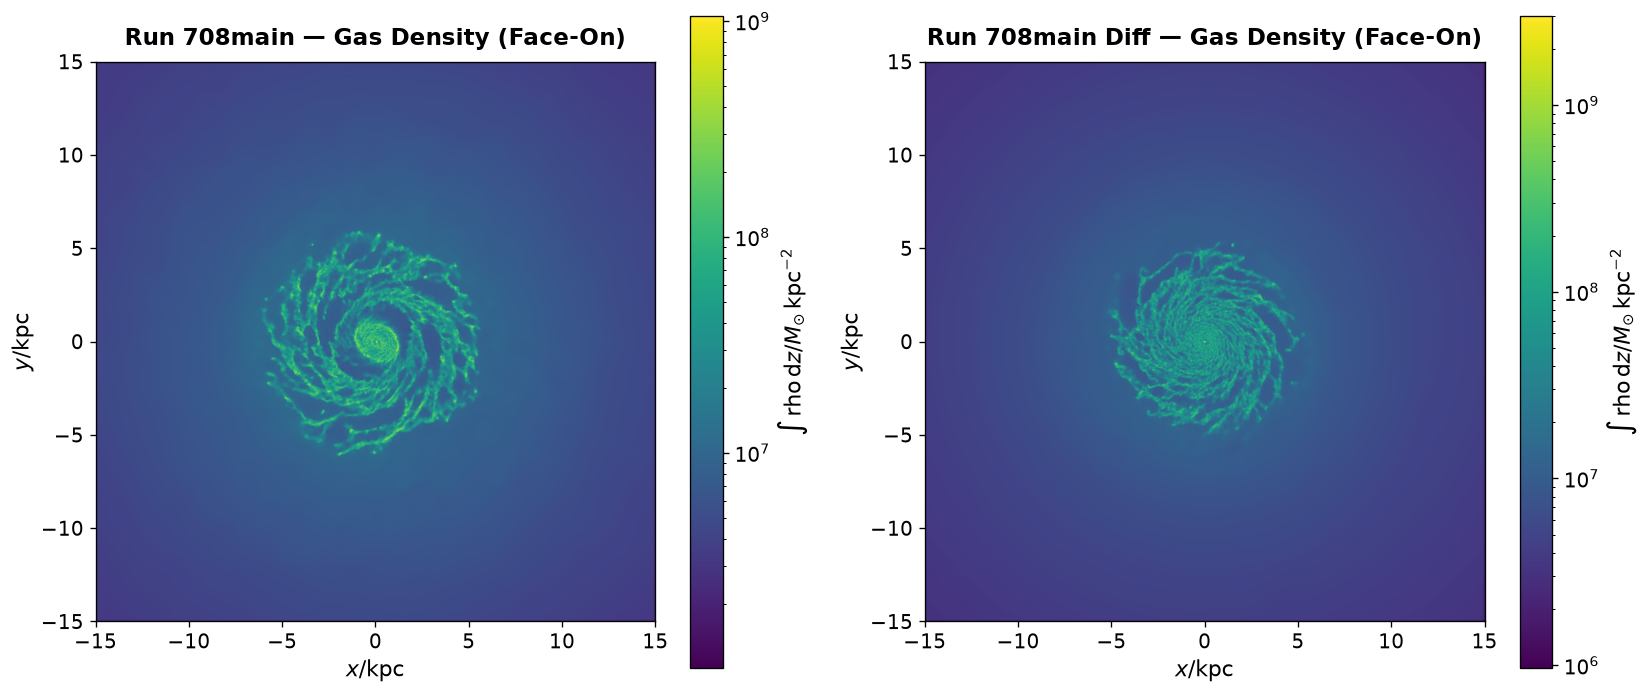

Saved as Task1_4_Gas_FaceOn.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

print("Rendering Run 708main gas map...")
render_sph_on_ax(
    s_main.g, axes[0],
    qty='rho', units='Msol kpc^-2', width='30 kpc', cmap='viridis',
    title='Run 708main — Gas Density (Face-On)'
)

print("Rendering Run 708main Diff gas map...")
render_sph_on_ax(
    s_diff.g, axes[1],
    qty='rho', units='Msol kpc^-2', width='30 kpc', cmap='viridis',
    title='Run 708main Diff — Gas Density (Face-On)'
)

plt.tight_layout()
plt.savefig('Task1_4_Gas_FaceOn.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved as Task1_4_Gas_FaceOn.png")

Calculating profile for Run 708main...
Calculating profile for Run 708main Diff...


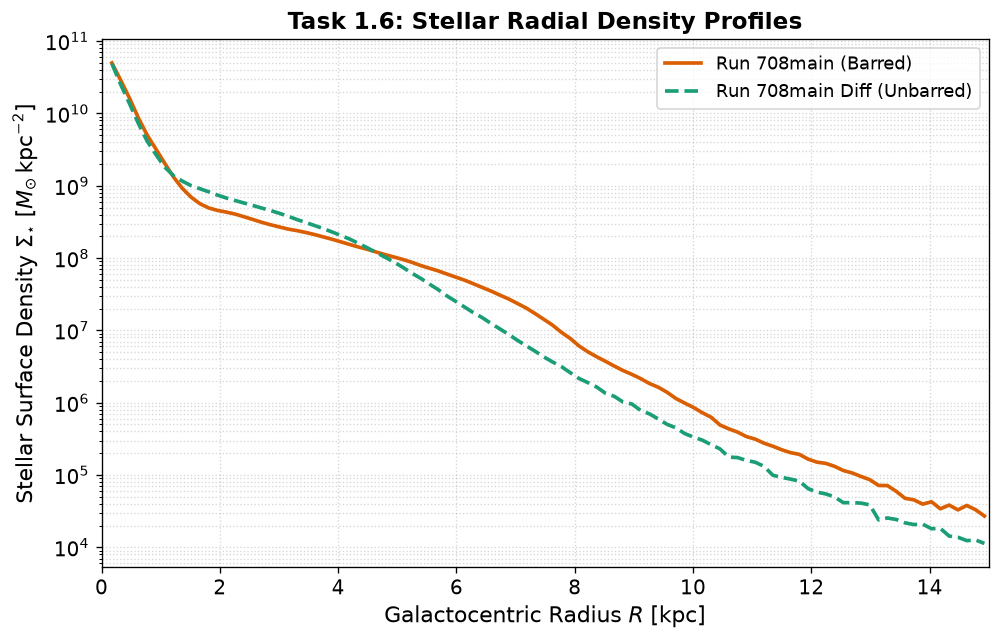

In [6]:
def compute_radial_profile(sim, rmax_kpc=15.0, bins=100):
    pos = np.array(sim.s['pos'])
    mass = np.array(sim.s['mass'])
    
    # Calculate cylindrical radius R = sqrt(x^2 + y^2)
    R = np.hypot(pos[:, 0], pos[:, 1])
    
    # Create radial bins
    rbins = np.linspace(0.1, rmax_kpc, bins + 1)
    rcenters = 0.5 * (rbins[1:] + rbins[:-1])
    
    # Calculate mass in each annulus
    mass_in_bins, _ = np.histogram(R, bins=rbins, weights=mass)
    
    # Calculate area of each annulus (A = pi * (r_out^2 - r_in^2))
    area = np.pi * (rbins[1:]**2 - rbins[:-1]**2)
    
    # Surface density (Sigma) = Mass / Area
    sigma = mass_in_bins / area
    return rcenters, sigma

print("Calculating profile for Run 708main...")
R_main, sigma_main = compute_radial_profile(s_main)

print("Calculating profile for Run 708main Diff...")
R_diff, sigma_diff = compute_radial_profile(s_diff)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(R_main, sigma_main, lw=2.2, color='#d95f02', label='Run 708main (Barred)')
ax.plot(R_diff, sigma_diff, lw=2.2, color='#1b9e77', ls='--', label='Run 708main Diff (Unbarred)')

ax.set_yscale('log')
ax.set_xlim(0, 15)
ax.set_xlabel(r'Galactocentric Radius $R$ [kpc]')
ax.set_ylabel(r'Stellar Surface Density $\Sigma_{\star}$ [$M_{\odot}\,\mathrm{kpc}^{-2}$]')
ax.set_title('Task 1.6: Stellar Radial Density Profiles', fontweight='bold')
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.savefig('Task1_6_Radial_Profiles.png', dpi=300, bbox_inches='tight')
plt.show()

Detected bar angle: 62.51 degrees
Rotating galaxy to align bar with x-axis...


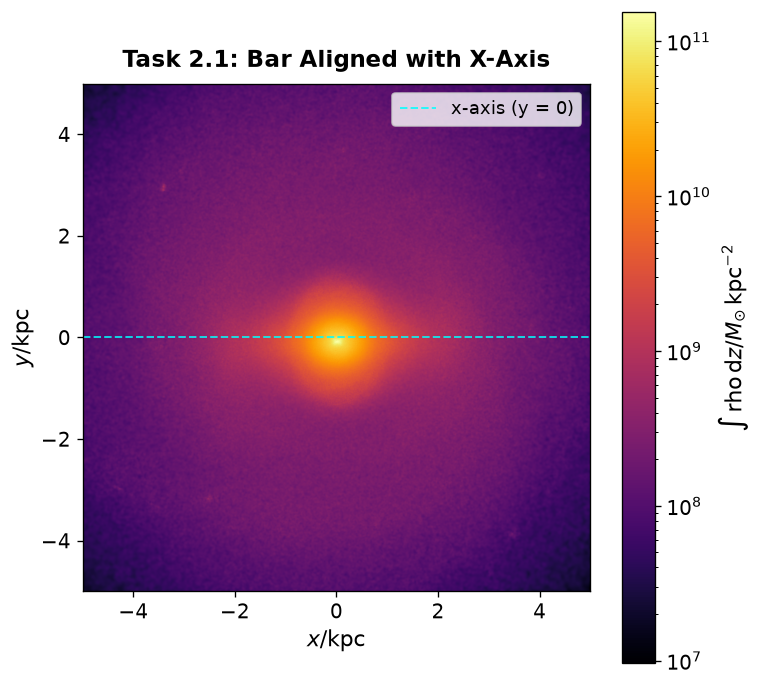

In [7]:
# 1. Isolate the barred galaxy
s_barred = s_main
name_barred = "Run 708main"

# 2. Calculate the bar position angle using the m=2 Fourier mode
pos = np.array(s_barred.s['pos'])
mass = np.array(s_barred.s['mass'])
R = np.hypot(pos[:, 0], pos[:, 1])

# Filter stars in the inner disk to isolate the bar (0.5 < R < 3.0 kpc)
mask = (R > 0.5) & (R < 3.0)
x_in = pos[mask, 0]
y_in = pos[mask, 1]
m_in = mass[mask]

phi = np.arctan2(y_in, x_in)
c2 = np.sum(m_in * np.cos(2.0 * phi))
s2 = np.sum(m_in * np.sin(2.0 * phi))
phi_bar_rad = 0.5 * np.arctan2(s2, c2)

print(f"Detected bar angle: {np.degrees(phi_bar_rad):.2f} degrees")

# 3. Rotate the entire galaxy by -phi_bar around the Z-axis (in-place pure NumPy)
cos_theta = np.cos(-phi_bar_rad)
sin_theta = np.sin(-phi_bar_rad)

R_z = np.array([
    [cos_theta, -sin_theta, 0],
    [sin_theta,  cos_theta, 0],
    [0,          0,         1]
])

print("Rotating galaxy to align bar with x-axis...")
s_barred['pos'][:] = np.dot(np.array(s_barred['pos']), R_z.T)
s_barred['vel'][:] = np.dot(np.array(s_barred['vel']), R_z.T)

# 4. Verify alignment visually
fig, ax = plt.subplots(figsize=(6.5, 6))
render_sph_on_ax(
    s_barred.s, ax,
    qty='rho', units='Msol kpc^-2', width='10 kpc', cmap='inferno',
    title='Task 2.1: Bar Aligned with X-Axis'
)
ax.axhline(0, color='cyan', ls='--', lw=1.2, alpha=0.8, label='x-axis (y = 0)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('Task2_1_Bar_Aligned.png', dpi=300, bbox_inches='tight')
plt.show()

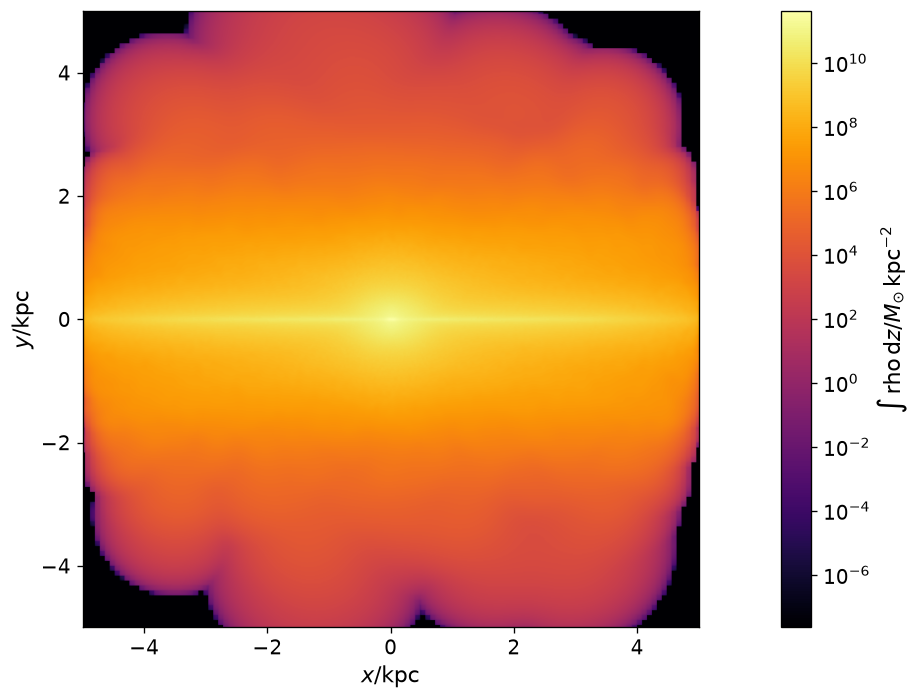

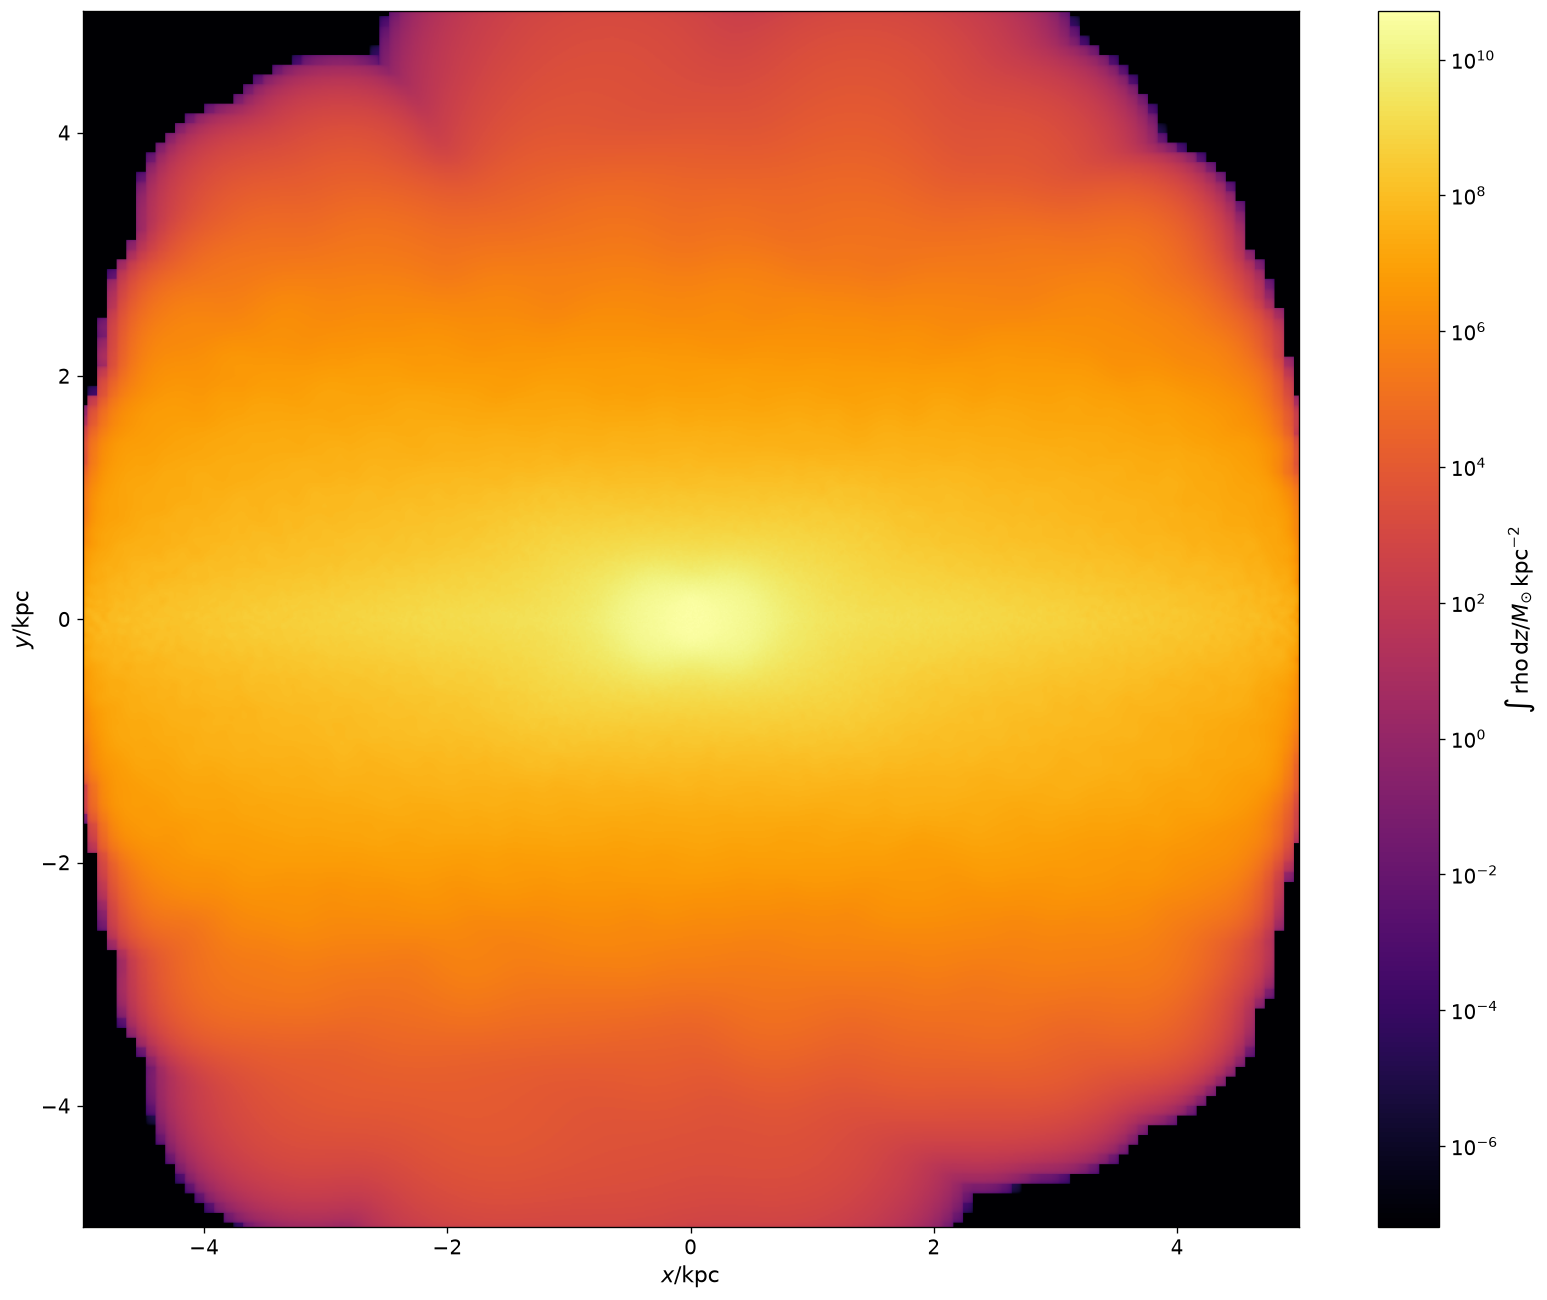

In [8]:
# 1. Rotate both galaxies 90 degrees around X-axis (Tip edge-on)
R_x = np.array([
    [1, 0,  0],
    [0, 0, -1],
    [0, 1,  0]
])

for sim in [s_main, s_diff]:
    sim['pos'][:] = np.dot(np.array(sim['pos']), R_x.T)
    sim['vel'][:] = np.dot(np.array(sim['vel']), R_x.T)

# 2. Pure NumPy spherical filter (r < 5 kpc)
def filter_sphere(sim, r_kpc):
    pos = np.array(sim.s['pos'])
    r = np.linalg.norm(pos, axis=1)
    mask = r < r_kpc
    return sim.s[mask]

s_main_inner = filter_sphere(s_main, 5.0)
s_diff_inner = filter_sphere(s_diff, 5.0)

# 3. Render the total side-on comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sph.image(s_main_inner, qty='rho', units='Msol kpc^-2', width='10 kpc', cmap='inferno', subplot=axes[0])
axes[0].set_title('Run 708main (Side-On, r < 5 kpc) — B/P Bulge', fontweight='bold', pad=10)

sph.image(s_diff_inner, qty='rho', units='Msol kpc^-2', width='10 kpc', cmap='inferno', subplot=axes[1])
axes[1].set_title('Run 708main Diff (Side-On, r < 5 kpc) — Unbarred', fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig('Task2_2A_SideOn_Comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# 4. Render the B/P bulge by Stellar Age
ages = np.array(s_main_inner['age'].in_units('Gyr'))
age_bins = [
    (0, 2.5, 'Young (0 – 2.5 Gyr)'),
    (2.5, 5.0, 'Int-Young (2.5 – 5.0 Gyr)'),
    (5.0, 7.5, 'Int-Old (5.0 – 7.5 Gyr)'),
    (7.5, 10.5, 'Old (7.5 – 10.0 Gyr)')
]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (amin, amax, label) in zip(axes.flatten(), age_bins):
    age_mask = (ages >= amin) & (ages < amax)
    sub_stars = s_main_inner[age_mask]
    
    sph.image(sub_stars, qty='rho', units='Msol kpc^-2', width='10 kpc', cmap='inferno', subplot=ax)
    ax.set_title(f'Run 708main: {label}', fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig('Task2_2B_BP_By_Age.png', dpi=300, bbox_inches='tight')
plt.show()

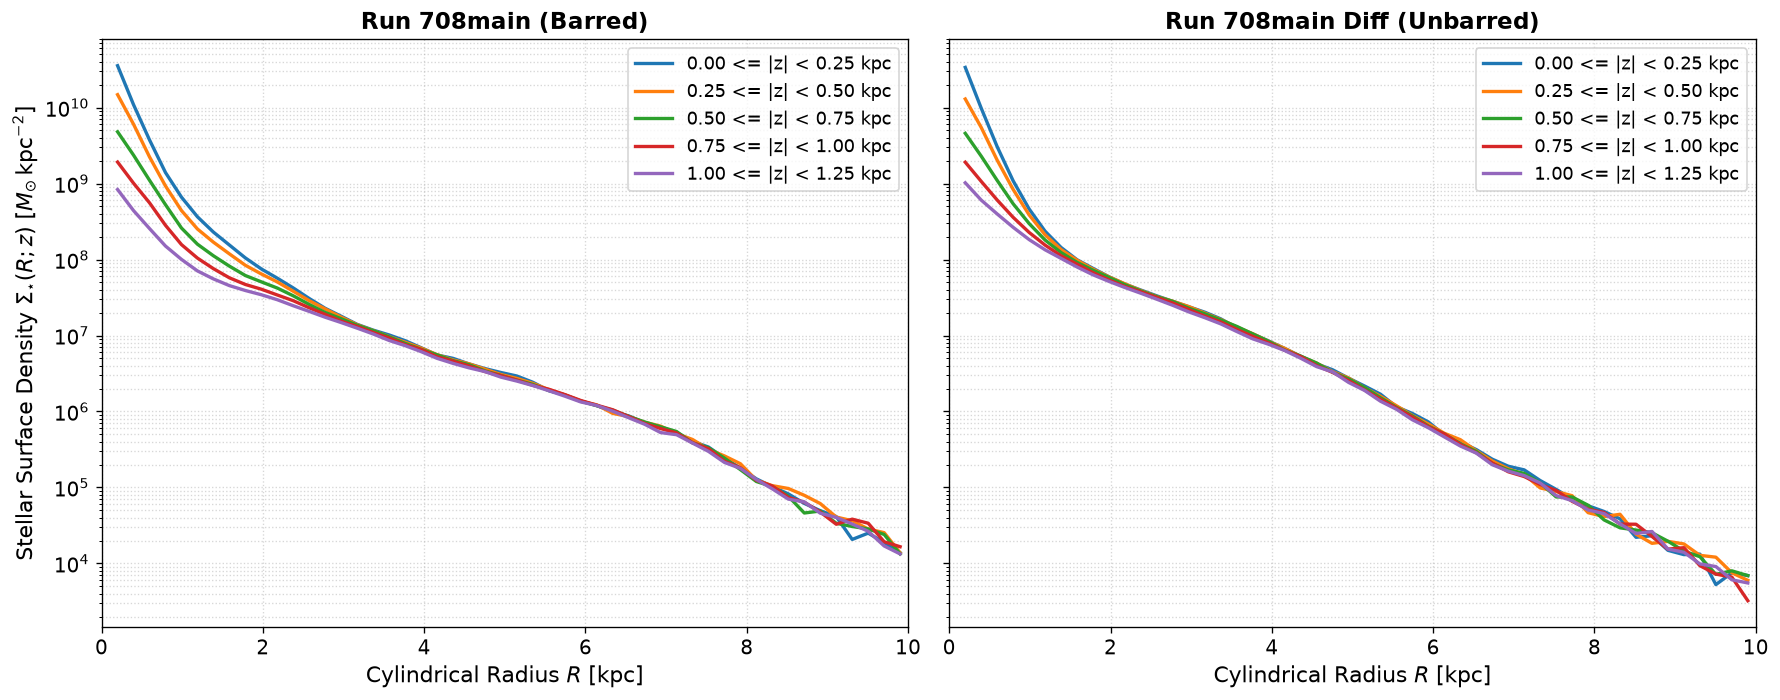

=== Task 2.5: Star Formation in B/P Bulge ===
Total stars in bulge slice (0.75 <= |z| <= 1.0 kpc): 499,413
Newly formed stars (age < 0.5 Gyr) in this region  : 19,481
Percentage of newly formed stars                   : 3.9008%


In [9]:
def compute_z_slice_profile(sim, zmin, zmax, rmax_kpc=10.0, bins=50):
    pos = np.array(sim.s['pos'])
    mass = np.array(sim.s['mass'])
    
    # Filter by height |z|
    z_abs = np.abs(pos[:, 2])
    z_mask = (z_abs >= zmin) & (z_abs < zmax)
    
    pos_slice = pos[z_mask]
    mass_slice = mass[z_mask]
    
    R = np.hypot(pos_slice[:, 0], pos_slice[:, 1])
    rbins = np.linspace(0.1, rmax_kpc, bins + 1)
    rcenters = 0.5 * (rbins[1:] + rbins[:-1])
    
    mass_in_bins, _ = np.histogram(R, bins=rbins, weights=mass_slice)
    area = np.pi * (rbins[1:]**2 - rbins[:-1]**2)
    
    return rcenters, mass_in_bins / area

# Define height slices
z_slices = [(0.0, 0.25), (0.25, 0.50), (0.50, 0.75), (0.75, 1.00), (1.00, 1.25)]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for (zmin, zmax), col in zip(z_slices, colors):
    label = f'{zmin:.2f} <= |z| < {zmax:.2f} kpc'
    
    R_bar, sig_bar = compute_z_slice_profile(s_main, zmin, zmax)
    axes[0].plot(R_bar, sig_bar, lw=2.0, color=col, label=label)
    
    R_unbar, sig_unbar = compute_z_slice_profile(s_diff, zmin, zmax)
    axes[1].plot(R_unbar, sig_unbar, lw=2.0, color=col, label=label)

for ax, title in zip(axes, ['Run 708main (Barred)', 'Run 708main Diff (Unbarred)']):
    ax.set_yscale('log')
    ax.set_xlim(0, 10)
    ax.set_xlabel(r'Cylindrical Radius $R$ [kpc]')
    ax.set_title(title, fontweight='bold')
    ax.grid(True, which='both', ls=':', alpha=0.5)
    ax.legend()

axes[0].set_ylabel(r'Stellar Surface Density $\Sigma_{\star}(R; z)$ [$M_{\odot}\,\mathrm{kpc}^{-2}$]')
plt.tight_layout()
plt.savefig('Task2_3_Profiles_By_Height.png', dpi=300, bbox_inches='tight')
plt.show()

# Task 2.5: Calculate Newly Formed Stars in the Bulge
pos_main = np.array(s_main.s['pos'])
ages_main = np.array(s_main.s['age'].in_units('Gyr'))
R_main = np.hypot(pos_main[:, 0], pos_main[:, 1])
z_abs_main = np.abs(pos_main[:, 2])

# Filter for the high-z bulge region (R < 3 kpc, 0.75 <= |z| <= 1.0 kpc)
bulge_mask = (R_main < 3.0) & (z_abs_main >= 0.75) & (z_abs_main <= 1.0)
bulge_ages = ages_main[bulge_mask]

n_new_500Myr = np.sum(bulge_ages < 0.5)
n_tot_bulge = len(bulge_ages)

print(f"=== Task 2.5: Star Formation in B/P Bulge ===")
print(f"Total stars in bulge slice (0.75 <= |z| <= 1.0 kpc): {n_tot_bulge:,}")
print(f"Newly formed stars (age < 0.5 Gyr) in this region  : {n_new_500Myr:,}")
if n_tot_bulge > 0:
    print(f"Percentage of newly formed stars                   : {(n_new_500Myr/n_tot_bulge)*100:.4f}%")

Calculating age-segregated profiles at 0.75 <= |z| <= 1.0 kpc...


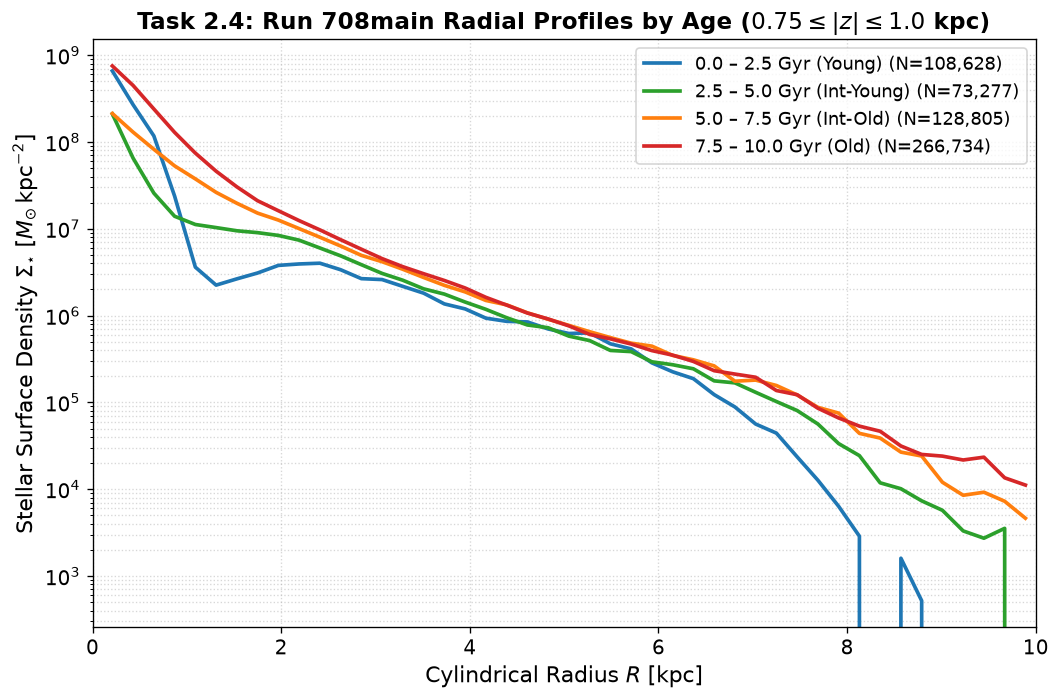

In [10]:
def compute_z_slice_profile_by_age(sim, zmin, zmax, rmax_kpc=10.0, bins=45):
    pos = np.array(sim.s['pos'])
    mass = np.array(sim.s['mass'])
    ages = np.array(sim.s['age'].in_units('Gyr'))
    
    # Isolate stars in the specified z-slice
    z_abs = np.abs(pos[:, 2])
    z_mask = (z_abs >= zmin) & (z_abs <= zmax)
    
    pos_slice = pos[z_mask]
    mass_slice = mass[z_mask]
    ages_slice = ages[z_mask]
    R_slice = np.hypot(pos_slice[:, 0], pos_slice[:, 1])
    
    rbins = np.linspace(0.1, rmax_kpc, bins + 1)
    rcenters = 0.5 * (rbins[1:] + rbins[:-1])
    area = np.pi * (rbins[1:]**2 - rbins[:-1]**2)
    
    # Define age bins
    age_bins = [
        (0.0, 2.5, '0.0 – 2.5 Gyr (Young)', '#1f77b4'),
        (2.5, 5.0, '2.5 – 5.0 Gyr (Int-Young)', '#2ca02c'),
        (5.0, 7.5, '5.0 – 7.5 Gyr (Int-Old)', '#ff7f0e'),
        (7.5, 10.5, '7.5 – 10.0 Gyr (Old)', '#d62728')
    ]
    
    profiles = {}
    for amin, amax, label, col in age_bins:
        age_mask = (ages_slice >= amin) & (ages_slice < amax)
        if np.sum(age_mask) > 100:
            mass_in_bins, _ = np.histogram(R_slice[age_mask], bins=rbins, weights=mass_slice[age_mask])
            profiles[label] = {
                'density': mass_in_bins / area,
                'color': col,
                'count': np.sum(age_mask)
            }
    
    return rcenters, profiles

# Execute for the barred galaxy
print("Calculating age-segregated profiles at 0.75 <= |z| <= 1.0 kpc...")
rcenters, age_profiles = compute_z_slice_profile_by_age(s_main, 0.75, 1.0)

# Plotting
fig, ax = plt.subplots(figsize=(9, 6))

for label, data in age_profiles.items():
    ax.plot(rcenters, data['density'], lw=2.2, color=data['color'], 
            label=f"{label} (N={data['count']:,})")

ax.set_yscale('log')
ax.set_xlim(0, 10)
ax.set_xlabel(r'Cylindrical Radius $R$ [kpc]')
ax.set_ylabel(r'Stellar Surface Density $\Sigma_{\star}$ [$M_{\odot}\,\mathrm{kpc}^{-2}$]')
ax.set_title(r'Task 2.4: Run 708main Radial Profiles by Age ($0.75 \leq |z| \leq 1.0$ kpc)', fontweight='bold')
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.savefig('Task2_4_Profiles_By_Age.png', dpi=300, bbox_inches='tight')
plt.show()